# Revisión de calidad
Revisa nulos, duplicados, edades imposibles y segmentos de longitud cero en los datos de data/raw, que se obtienen con dvc pull. Complementa el perfilamiento de src/exploracion/perfilamiento.py.

In [24]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent 
sys.path.insert(0, str(RAIZ))
from src.exploracion.perfilamiento import longitud_proyectada
%matplotlib inline
RAW = RAIZ / "data" / "raw"
capas = {"malla": pd.read_parquet(RAW / "malla_vial_integral.parquet"),
    "siniestros": pd.read_parquet(RAW / "historico_siniestros.parquet"),
    "victimas": pd.read_parquet(RAW / "victimas_2021_2025.parquet"),
    "intervenciones": pd.read_parquet(RAW / "intervenciones_seguridad_vial.parquet")}
{nombre: df.shape for nombre, df in capas.items()}


{'malla': (139107, 12),
 'siniestros': (209861, 12),
 'victimas': (94902, 15),
 'intervenciones': (27950, 10)}

## 1. Nulos y vacíos
Se cuentan como faltantes los nulos y los textos vacíos o con solo espacios

In [25]:
filas = []
for nombre, df in capas.items():
    texto = df.select_dtypes("object").drop(columns=["geometry"], errors="ignore")
    vacios = texto.apply(lambda s: s.astype(str).str.strip().eq("").sum())
    for columna in df.columns.drop("geometry", errors="ignore"):
        nulos = int(df[columna].isna().sum())
        en_blanco = int(vacios.get(columna, 0))
        if nulos or en_blanco:
            filas.append({
                "capa": nombre,
                "columna": columna,
                "nulos": nulos,
                "vacios": en_blanco,
                "%": round(100 * (nulos + en_blanco) / len(df), 1)})
faltantes = pd.DataFrame(filas).sort_values("%", ascending=False)
faltantes

,capa,columna,nulos,vacios,%
8,victimas,MUERTE_POSTERIOR,92617,0,97.6
1,malla,MVIVELREG,56377,0,40.5
5,victimas,LOCALIDAD,8663,0,9.1
0,malla,MVITIPO,2506,5082,5.5
3,malla,MVINOMBRE,0,3313,2.4
2,malla,MVICCALZAD,762,0,0.5
7,victimas,EDAD,369,0,0.4
6,victimas,GENERO,354,0,0.4
4,siniestros,LOCALIDAD,0,46,0.0
9,victimas,LOCNOMBRE,11,0,0.0


In [26]:
victimas = capas["victimas"]


In [27]:
print("MUERTE_POSTERIOR vacía:", victimas.MUERTE_POSTERIOR.isna().sum())
print("Víctimas lesionadas:", victimas.TIPO_VICTIMA.eq("Lesionado").sum())
bool((victimas.MUERTE_POSTERIOR.isna() == victimas.TIPO_VICTIMA.eq("Lesionado")).all())

MUERTE_POSTERIOR vacía: 92617
Víctimas lesionadas: 92617


True

El campo MUERTE_POSTERIOR concentra el 97,6 % de faltantes, el más alto de la tabla, pero no es un problema de calidad: indica si la víctima murió después del siniestro, así que solo aplica a los fallecidos. La verificación anterior da verdaero: el campo está vacío exactamente en los 92.617 registros de víctimas lesionadas y lleno en todos los fallecidos.

## 2. Duplicados
Filas idénticas, identificador y llave de negocio repetida en cada capa

In [28]:
duplicados = pd.DataFrame({
    nombre: {
        "filas_identicas": int(df.drop(columns=["geometry"], errors="ignore").duplicated().sum()),
        "OBJECTID_repetido": int(df.OBJECTID.duplicated().sum()),
    }
    for nombre, df in capas.items()
}).T
duplicados["llave_repetida"] = [
    int(capas["malla"].MVICIV[capas["malla"].MVICIV != 0].duplicated().sum()),
    int(capas["siniestros"].FORMULARIO.duplicated().sum()),
    int(victimas.CODIGO_ACCIDENTADO.duplicated().sum()),
    int(capas["intervenciones"].duplicated(["CIV", "CATEGORIA", "FECHA_FIN_"]).sum()),
]
duplicados

,filas_identicas,OBJECTID_repetido,llave_repetida
malla,0,0,20898
siniestros,0,0,0
victimas,0,0,0
intervenciones,0,0,9678


## 3. Edades imposibles
Se consideran implausibles las edades de 0 y las mayores de 100 años, el mismo criterio del perfilamiento.

Edad nula: 369
Edad 0: 187
Edad mayor a 100: 149


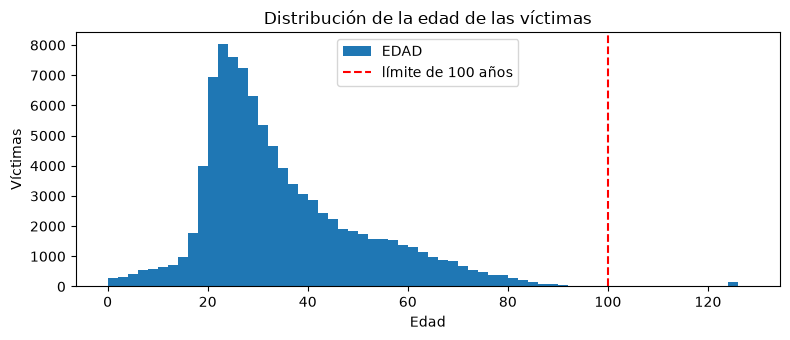

In [29]:
print("Edad nula:", victimas.EDAD.isna().sum())
print("Edad 0:", (victimas.EDAD == 0).sum())
print("Edad mayor a 100:", (victimas.EDAD > 100).sum())

ax = victimas.EDAD.plot.hist(bins=range(0, 130, 2), figsize=(8, 3.5))
ax.axvline(100, color="red", linestyle="--", label="límite de 100 años")
ax.set_xlabel("Edad")
ax.set_ylabel("Víctimas")
ax.set_title("Distribución de la edad de las víctimas")
ax.legend()
plt.tight_layout()

In [30]:
victimas[
    victimas.CONDICION.isin(["CONDUCTOR", "MOTOCICLISTA"]) & victimas.EDAD.between(1, 15)
].groupby("CONDICION").size()

CONDICION
CONDUCTOR       14
MOTOCICLISTA    79
dtype: int64

## 4. Segmentos de longitud cero
La longitud de cada tramo se calcula en metros sobre la geometría en EPSG:3116, con la misma función del perfilamiento.

Menores a 1 m: 47


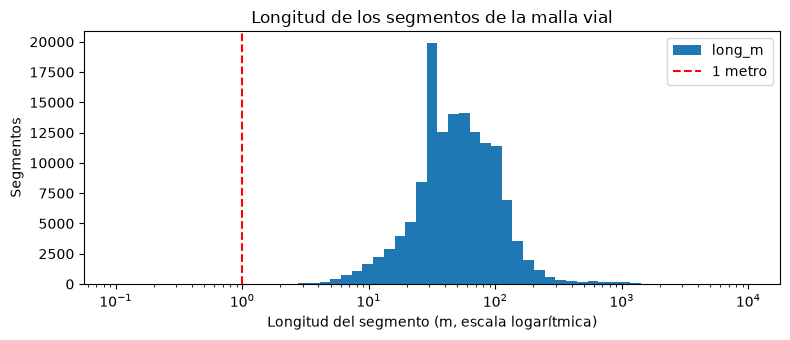

In [31]:
malla = capas["malla"]
malla["long_m"] = malla.geometry.map(longitud_proyectada)
print("Menores a 1 m:", (malla.long_m < 1).sum())

ax = malla.long_m.clip(lower=0.1).plot.hist(
    bins=np.logspace(-1, 4, 60), figsize=(8, 3.5), logx=True
)
ax.axvline(1, color="red", linestyle="--", label="1 metro")
ax.set_xlabel("Longitud del segmento (m, escala logarítmica)")
ax.set_ylabel("Segmentos")
ax.set_title("Longitud de los segmentos de la malla vial")
ax.legend()
plt.tight_layout()

In [32]:
por_capa = pd.DataFrame({
    nombre: {
        "registros": len(df),
        "campos_con_faltantes": int((faltantes.capa == nombre).sum()),
        "valores_faltantes": int(faltantes.loc[faltantes.capa == nombre, ["nulos", "vacios"]].to_numpy().sum()),
        "filas_identicas": duplicados.loc[nombre, "filas_identicas"],
        "OBJECTID_repetido": duplicados.loc[nombre, "OBJECTID_repetido"],
    }
    for nombre, df in capas.items()
}).T
por_capa

,registros,campos_con_faltantes,valores_faltantes,filas_identicas,OBJECTID_repetido
malla,139107,4,68040,0,0
siniestros,209861,1,46,0,0
victimas,94902,6,102025,0,0
intervenciones,27950,1,1,0,0


## Conclusiones
- **Faltantes.** El faltante que más afecta al modelo es la velocidad reglamentada de la malla: falta en el 40,5 % de los segmentos y habrá que imputarla. En las víctimas, el 9,1 % no tiene localidad registrada. El 97,6 % de faltantes en MUERTE_POSTERIOR no es un defecto: solo aplica a fallecidos.
- **Duplicados.** Ninguna capa tiene filas idénticas ni OBJECTID repetidos. En siniestros, cada FORMULARIO es único, lo que respalda el cruce de víctimas y siniestros por ese campo. Los 20.898 registros de la malla con un CIV repetido no son errores: un mismo CIV agrupa varios tramos de la malla (por calzada o por eje vial), y su longitud se obtiene sumando esos tramos. En intervenciones hay 9.678 registros que repiten CIV, categoría y fecha; hay que confirmar si son intervenciones distintas en el mismo tramo antes de contarlas por segmento.
- **Edades.** 369 víctimas no tienen edad, 187 tienen edad 0 y 149 superan los 100 años: en total 705 registros (0,7 %), que se excluyen de los grupos de edad. Además hay 14 conductores y 79 motociclistas menores de 16 años, edad en la que no se puede tener licencia de conducción; pueden ser errores en la edad o en la condición registrada.
- **Longitudes.** 47 segmentos de la malla miden menos de 1 metro. Con una longitud casi nula, cualquier siniestro asignado a ellos daría una tasa por metro desproporcionada, así que conviene excluirlos o fusionarlos con el segmento vecino antes de modelar